In [93]:
import numpy as np
from hcipy import *
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from adcFitter_onsky import AdcFitter

In [94]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = AdcFitter(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle) 

In [200]:
#fitting functions
from scipy.optimize import curve_fit

def gauss(x,mu,sigma2):
    return np.exp(-(x-mu)**2 / (2 * sigma2) )

def isolate_gaussian(data):
    new_data = data.copy()

    mid = np.argmax(new_data)
    first_derivative = np.gradient(new_data) 

    valley_indices = np.where((first_derivative[:-1] < 0) & (first_derivative[1:] > 0))[0] + 1

    left_valley = valley_indices[valley_indices < mid][-1] if any(valley_indices < mid) else None
    right_valley = valley_indices[valley_indices > mid][0] if any(valley_indices > mid) else None

    if left_valley is not None:
        new_data[0:left_valley] = 0
        #right_valley -= left_valley

    if right_valley is not None:
        new_data[right_valley:len(new_data)] = 0
        #print(right_valley)

    return new_data


def mu(data):
    isolated = isolate_gaussian(data)
    x = np.arange(len(data))
    popt = curve_fit(gauss,x,isolated,p0=[np.argmax(data),2])

    mu = popt[0][0]
    sigma = popt[0][1]
    fwhm = 2 * np.sqrt(2 * np.log(2)) * np.sqrt(sigma)
    return mu, sigma, fwhm
    

(160000,)

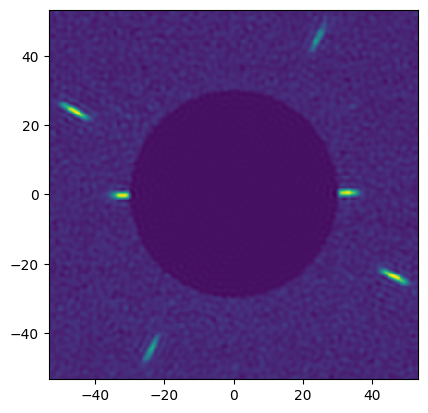

In [207]:
img = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/sats/7725_0offset.fits')[0]
img = ADC.filter_image(ADC.crop_image((img)))


#img = img_cube[3]
imshow_field(img)
img.shape

[ 0.         54.73780488]


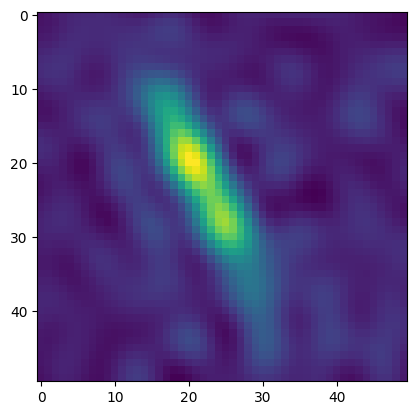

In [273]:
#cut out the speckle window
speckle_number = 0

#locate the general area of the speckle
extent=20
speckle_coords = np.array([[0, ADC.grating_freq * ADC.normalized_wavelength],[ADC.grating_freq * ADC.normalized_wavelength,0],[0, -ADC.grating_freq * ADC.normalized_wavelength],[-ADC.grating_freq * ADC.normalized_wavelength,0]])
speckle_center = speckle_coords[0]
print(speckle_center)

#cut out the speckle area
rect = make_rotated_aperture(make_rectangular_aperture(size=(extent,extent), center=speckle_coords[speckle_number]), np.deg2rad(-grating_angle))(img.grid)
speckle_img = rect * img

#find the center of intensity of the speckle area and window the image around that center
center_of_intensity = np.array([sum(speckle_img*speckle_img.grid.x)/sum(speckle_img),sum(speckle_img*speckle_img.grid.y)/sum(speckle_img)])
window_size=50
new_img = ADC.window_field(img,[center_of_intensity[0],center_of_intensity[1]],window_size,window_size)

#tada!
#imshow_field(new_img)
plt.imshow(new_img.shaped)

In [274]:
#now iterate through all the slices
shaped = new_img.shaped
mus = np.zeros(shaped.shape[0])
zscores = np.zeros(shaped.shape[0])
maxes = np.zeros(shaped.shape[0])

snr_threshold = 2


for i in range(shaped.shape[0]): #in np.array([40,0]):
    if speckle_number % 2 != 0: #columns vs rows depending on which speckle it is
        sliced = shaped[:,i]
    else: sliced = shaped[i,:]

    zscore = (np.max(sliced) - np.mean(sliced))/np.std(sliced)
    zscores[i] = zscore

    if zscore > snr_threshold:
        s = isolate_gaussian(sliced)
        s /= s.max()
        m, std, fwhm = mu(s)
        mus[i] = m
    else: mus[i] = -1


Text(0, 0.5, 'row index of mean position')

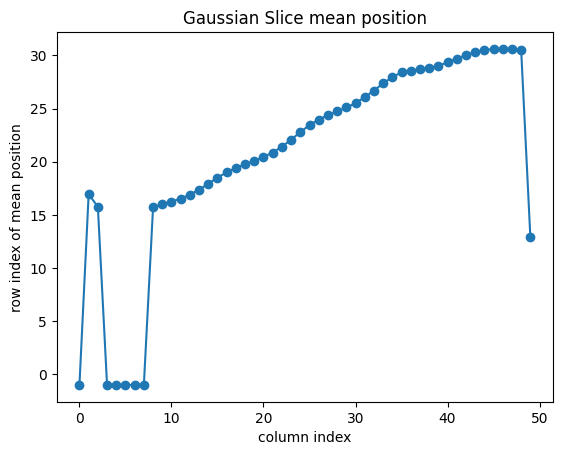

In [275]:
#plot the means
plt.plot(mus,'-o')
plt.title('Gaussian Slice mean position')
plt.xlabel('column index')
plt.ylabel('row index of mean position')

slope: 0.44
corresponding angle: 0.41 (rad) or 23.51°


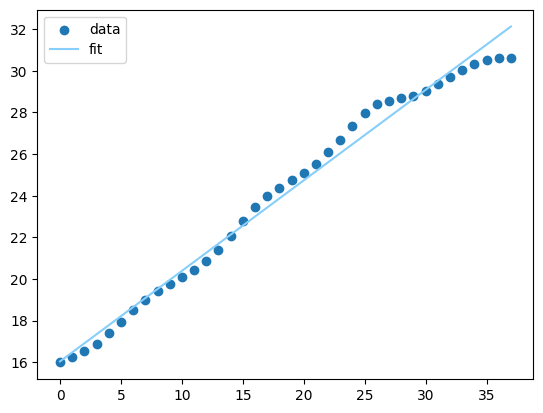

In [276]:
#plot the linear region
deriv2 = np.gradient(np.gradient(mus))

nonlin_region = np.squeeze(np.where(np.abs(deriv2) > 0.4))

midpoint = 20
leftbound = nonlin_region[nonlin_region < midpoint][-1]
rightbound = nonlin_region[nonlin_region > midpoint][0]


linear_region = mus[leftbound:rightbound]
lin_x = np.arange(len(linear_region))

m , b = np.polyfit(lin_x,linear_region,deg=1)
angle = np.arctan(m)
print(f'slope: {m:.2f}\ncorresponding angle: {angle:.2f} (rad) or {np.degrees(angle):.2f}°')
plt.scatter(lin_x,linear_region,label='data')
plt.plot(lin_x, m * lin_x + b,label='fit',color='LightSkyBlue')
plt.legend()
plt.show()

In [271]:
#define a function
def slice_speckle_angle(img,speckle_number):
    print(img.shape)
    extent=20
    speckle_coords = np.array([[0, ADC.grating_freq * ADC.normalized_wavelength],[ADC.grating_freq * ADC.normalized_wavelength,0],[0, -ADC.grating_freq * ADC.normalized_wavelength],[-ADC.grating_freq * ADC.normalized_wavelength,0]])

    rect = make_rotated_aperture(make_rectangular_aperture(size=(extent,extent), center=speckle_coords[speckle_number]), np.deg2rad(-grating_angle))(img.grid)
    speckle_img = rect * img

    center_of_intensity = np.array([sum(speckle_img*speckle_img.grid.x)/sum(speckle_img),sum(speckle_img*speckle_img.grid.y)/sum(speckle_img)])
    window_size=40
    new_img = ADC.window_field(speckle_img,[center_of_intensity[0],center_of_intensity[1]],window_size,window_size)

    shaped = new_img.shaped
    mus = np.zeros(shaped.shape[0])

    
    snr_threshold = 2


    for i in range(shaped.shape[0]): #in np.array([40,0]):
        if speckle_number % 2 != 0: #columns vs rows depending on which speckle it is
            sliced = shaped[:,i]
        else: sliced = shaped[i,:]

        zscore = (np.max(sliced) - np.mean(sliced))/np.std(sliced)
        zscores[i] = zscore

        if zscore > snr_threshold:
            s = isolate_gaussian(sliced)
            s /= s.max()
            m, std, fwhm = mu(s)
            mus[i] = m
        else: mus[i] = -1

    # for i in range(shaped.shape[0]):
    #     if speckle_number % 2 != 0: #columns vs rows depending on which speckle it is
    #         sliced = shaped[:,i]
    #     else: sliced = shaped[i,:]
    #     s = isolate_gaussian(sliced)
    #     s /= s.max()
    #     m, std, fwhm = mu(s)
    #     mus[i] = m

    
    deriv2 = np.gradient(np.gradient(mus))
    nonlin_region = np.squeeze(np.where(np.abs(deriv2) > 0.4))

    midpoint = window_size/2
    leftbound = nonlin_region[nonlin_region < midpoint][-1]
    rightbound = nonlin_region[nonlin_region > midpoint][0]

    linear_region = mus[leftbound:rightbound]
    lin_x = np.arange(len(linear_region))

    m , b = np.polyfit(lin_x,linear_region,deg=1)
    angle = np.arctan(m)
    #print(f'slope: {m:.2f}\ncorresponding angle: {angle:.2f} (rad) or {np.degrees(angle):.2f}°')
    angle = np.degrees(angle)

    return angle #returns the angle in DEGREES

In [269]:
#now find the speckle angles for all four 
def all_speckle_angles(img):
    angles = np.zeros(4)
    for i in range(4):
        print(i)
        angles[i] = slice_speckle_angle(img,i)
    return angles

In [ ]:
#now find all four for an entire calibration dataset to see if you can create a response in the same way as before
# fieldcube = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/nov9th/counterrotation.fits')
# img_cube = []

# for i, field in enumerate(fieldcube):
#     filtered = ADC.filter_image(ADC.crop_image(field,mask_diam=60)) 
#     filtered = Field(np.array([x if x > 0 else 0 for x in filtered ]),filtered.grid)

#     img_cube.append(filtered)


In [171]:
fieldcube = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/sats/7725_0offset.fits')
#img = ADC.filter_image(ADC.crop_image((img)))
img_cube = []

for i, field in enumerate(fieldcube):
    filtered = ADC.filter_image(ADC.crop_image(field,mask_diam=60)) 
    #filtered = Field(np.array([x if x > 0 else 0 for x in filtered ]),filtered.grid)

    img_cube.append(filtered)

In [272]:
all_angles = []
iter = 0
for img in img_cube[0:5]:
    print(iter)
    a = all_speckle_angles(img)
    all_angles.append(a)
    iter +=1

0
0
(160000,)


IndexError: index 0 is out of bounds for axis 0 with size 0

In [169]:
print(all_angles)

[]
